# Projeto Final - Fundamentos de Machine Learning

**Integrantes do Grupo:** Charlene, Cinthia, Cristiane e Douglas  
**Base de Dados:** `estudantes_desempenho.CSV` (adaptação em português do *UCI Student Performance Dataset* — disciplina de Língua Portuguesa, escolas Gabriel Pereira - GP e Mousinho da Silveira - MS).  
**Fonte Original:** UCI Machine Learning Repository (`https://archive.ics.uci.edu/dataset/320/student+performance`) — 649 linhas (estudantes) e 33 colunas originais.

---

# Etapa 1: Descrição do Problema

> **Enunciado da Especificação (Etapa 1):** *"1. Descrição do problema: o que vocês querem prever, classificar ou agrupar, e por que isso importa. Que decisão o modelo apoiaria?"*

### 1.1 O que queremos prever, classificar e agrupar?
Neste projeto, investigamos o desempenho escolar dos estudantes aplicando três abordagens vistas na disciplina:
1. **Regressão (Supervisionada):** Prever a **`Nota_Final`** do estudante (valor numérico de `0` a `20` pontos).
2. **Classificação (Supervisionada):** Classificar o **`Risco_Reprovacao`** (`1` = Reprovado, com `Nota_Final < 10`, representando **15,41%** dos alunos; `0` = Aprovado, com `Nota_Final >= 10`, representando **84,59%**).
3. **Clusterização e PCA (Não Supervisionada):** Agrupar os estudantes em **perfis socioeconômicos e comportamentais** (usando K-Means e PCA, sem utilizar as notas no agrupamento) para identificar quais perfis concentram maior risco de baixo rendimento.

### 1.2 Por que isso importa e que decisão o modelo apoiaria?
A reprovação escolar gera evasão, desmotivação e custos adicionais para as escolas e famílias. Identificar estudantes vulneráveis somente após o fechamento das notas finais impede qualquer ação corretiva.
* **Decisão apoiada pelo modelo:** Apoiar a coordenação pedagógica na **alocação preventiva de tutoria, aulas de reforço escolar e acompanhamento familiar** em dois momentos distintos:
  * **Cenário A (Início do Ano Letivo — Sem Notas do 1º e 2º Períodos):** Identifica estudantes em risco logo na matrícula, usando apenas histórico escolar (`Reprovacoes_Anteriores`), rotina (`Tempo_de_Estudo_Semanal`, `Numero_de_Faltas`) e dados socioeconômicos.
  * **Cenário B (Final do 2º Período — Com Notas Parciais):** Atualiza a previsão antes do exame final para direcionar a recuperação intensiva.

# Projeto Final - Etapa 2: Pré-processamento e Análise Exploratória dos Dados (EDA)

> **Enunciado da Especificação (Etapa 2):** *"2. Pré-processamento e análise exploratória: tratamento de valores ausentes, normalização ou transformação, codificação de variáveis categóricas e uma EDA que justifique essas escolhas."*

Este notebook realiza a **Etapa 2 do projeto final** com a base `estudantes_desempenho.CSV`.

Objetivos: verificar a estrutura e qualidade dos dados, valores ausentes, duplicidades, tipos e inconsistências; analisar notas, faltas, tempo de estudo e reprovações; estudar relações com o desempenho; e preparar codificação e padronização para modelagem.

**Decisão adotada:** notas finais iguais a zero serão mantidas como valores válidos nesta etapa e não serão recalculadas.

## 2.1 Importação das bibliotecas

Usaremos `pandas` para manipulação, `numpy` para operações numéricas e `matplotlib`/`seaborn` para visualização.


In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler


pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2.2 Carregamento do CSV

O arquivo utiliza ponto e vírgula (`;`) como separador.


In [152]:
arquivo = "estudantes_desempenho.CSV"
df = pd.read_csv(arquivo, sep=";", encoding="latin-1")
df.head()


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
0,GP,Feminino,18,Urbano,Mais_de_3,Separados,4,4,Em_casa,Professor(a),Preferencia_pelo_curso,Mae,2,2,0,Sim,Não,Não,Não,Sim,Sim,Não,Não,4,3,4,1,1,3,4,0,11,11
1,GP,Feminino,17,Urbano,Mais_de_3,Juntos,1,1,Em_casa,Outro,Preferencia_pelo_curso,Pai,1,2,0,Não,Sim,Não,Não,Não,Sim,Sim,Não,5,3,3,1,1,3,2,9,11,11
2,GP,Feminino,15,Urbano,Ate_3,Juntos,1,1,Em_casa,Outro,Outro,Mae,1,2,0,Sim,Não,Não,Não,Sim,Sim,Sim,Não,4,3,2,2,3,3,6,12,13,12
3,GP,Feminino,15,Urbano,Mais_de_3,Juntos,4,2,Saude,Servicos,Proximidade_de_casa,Mae,1,3,0,Não,Sim,Não,Sim,Sim,Sim,Sim,Sim,3,2,2,1,1,5,0,14,14,14
4,GP,Feminino,16,Urbano,Mais_de_3,Juntos,3,3,Outro,Outro,Proximidade_de_casa,Pai,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,4,3,2,1,2,5,0,11,13,13


## 2.3 Dimensão e conferência da base

Cada linha representa um estudante e cada coluna uma característica.


In [153]:
print(f"A base possui {df.shape[0]} estudantes.")
print(f"A base possui {df.shape[1]} variáveis.")
df.sample(5, random_state=42)


A base possui 649 estudantes.
A base possui 33 variáveis.


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
636,MS,Masculino,18,Urbano,Mais_de_3,Juntos,4,4,Professor(a),Professor(a),Proximidade_de_casa,Pai,1,2,0,Não,Não,Não,Sim,Não,Sim,Sim,Não,3,2,4,1,4,2,4,17,18,19
220,GP,Feminino,16,Urbano,Mais_de_3,Separados,3,1,Servicos,Outro,Preferencia_pelo_curso,Mae,1,2,0,Não,Sim,Não,Não,Sim,Sim,Sim,Não,2,3,3,2,2,4,2,11,11,12
594,MS,Feminino,18,Urbano,Mais_de_3,Juntos,4,4,Professor(a),Professor(a),Reputacao_da_escola,Mae,2,2,0,Não,Não,Não,Sim,Não,Sim,Sim,Não,4,3,5,1,2,1,0,18,18,18
429,MS,Masculino,16,Rural,Ate_3,Separados,4,4,Em_casa,Outro,Proximidade_de_casa,Mae,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,5,3,2,1,3,2,5,10,11,11
72,GP,Feminino,15,Rural,Mais_de_3,Juntos,1,1,Outro,Outro,Reputacao_da_escola,Mae,1,2,0,Sim,Sim,Não,Não,Não,Sim,Sim,Sim,3,3,4,2,4,5,2,13,11,11


## 2.4 Colunas e tipos das variáveis

Removemos espaços externos dos nomes e observamos os tipos. Algumas colunas numéricas são categorias ordinais e devem ser interpretadas segundo suas escalas.


In [154]:
df.columns = df.columns.str.strip()
for numero, coluna in enumerate(df.columns, 1):
    print(f"{numero}: {coluna}")


1: Escola
2: Sexo
3: Idade
4: Tipo_de_Endereco
5: Tamanho_da_Familia
6: Situacao_dos_Pais
7: Escolaridade_da_Mae
8: Escolaridade_do_Pai
9: Ocupacao_da_Mae
10: Ocupacao_do_Pai
11: Motivo_da_Escolha_da_Escola
12: Responsavel
13: Tempo_de_Deslocamento
14: Tempo_de_Estudo_Semanal
15: Reprovacoes_Anteriores
16: Apoio_Educacional_da_Escola
17: Apoio_Educacional_Familiar
18: Aulas_Particulares_Pagas
19: Atividades_Extracurriculares
20: Frequentou_Educacao_Infantil
21: Pretende_Cursar_Ensino_Superior
22: Acesso_a_Internet_em_Casa
23: Relacionamento_Amoroso
24: Qualidade_das_Relacoes_Familiares
25: Tempo_Livre_Apos_a_Escola
26: Frequencia_de_Saidas_com_Amigos
27: Consumo_de_Alcool_em_Dias_Uteis
28: Consumo_de_Alcool_no_Fim_de_Semana
29: Estado_de_Saude_Atual
30: Numero_de_Faltas
31: Nota_1o_Periodo
32: Nota_2o_Periodo
33: Nota_Final


In [155]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Escola                              649 non-null    object
 1   Sexo                                649 non-null    object
 2   Idade                               649 non-null    int64 
 3   Tipo_de_Endereco                    649 non-null    object
 4   Tamanho_da_Familia                  649 non-null    object
 5   Situacao_dos_Pais                   649 non-null    object
 6   Escolaridade_da_Mae                 649 non-null    int64 
 7   Escolaridade_do_Pai                 649 non-null    int64 
 8   Ocupacao_da_Mae                     649 non-null    object
 9   Ocupacao_do_Pai                     649 non-null    object
 10  Motivo_da_Escolha_da_Escola         649 non-null    object
 11  Responsavel                         649 non-null    object

In [156]:
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(include="object").columns.tolist()
print("Numéricas:", colunas_numericas)
print("Categóricas:", colunas_categoricas)


Numéricas: ['Idade', 'Escolaridade_da_Mae', 'Escolaridade_do_Pai', 'Tempo_de_Deslocamento', 'Tempo_de_Estudo_Semanal', 'Reprovacoes_Anteriores', 'Qualidade_das_Relacoes_Familiares', 'Tempo_Livre_Apos_a_Escola', 'Frequencia_de_Saidas_com_Amigos', 'Consumo_de_Alcool_em_Dias_Uteis', 'Consumo_de_Alcool_no_Fim_de_Semana', 'Estado_de_Saude_Atual', 'Numero_de_Faltas', 'Nota_1o_Periodo', 'Nota_2o_Periodo', 'Nota_Final']
Categóricas: ['Escola', 'Sexo', 'Tipo_de_Endereco', 'Tamanho_da_Familia', 'Situacao_dos_Pais', 'Ocupacao_da_Mae', 'Ocupacao_do_Pai', 'Motivo_da_Escolha_da_Escola', 'Responsavel', 'Apoio_Educacional_da_Escola', 'Apoio_Educacional_Familiar', 'Aulas_Particulares_Pagas', 'Atividades_Extracurriculares', 'Frequentou_Educacao_Infantil', 'Pretende_Cursar_Ensino_Superior', 'Acesso_a_Internet_em_Casa', 'Relacionamento_Amoroso']


## 2.5 Limpeza simples dos textos

Removemos espaços externos e trocamos sublinhados por espaços somente nos valores categóricos para melhorar a leitura.


In [157]:
for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip().str.replace("_", " ", regex=False)


## 2.6 Valores ausentes

Verificamos quantidade e percentual de ausências.


In [158]:
valores_ausentes = df.isnull().sum()
percentual_ausentes = (df.isnull().mean() * 100).round(2)
analise_ausentes = pd.DataFrame({"Quantidade_Ausentes": valores_ausentes, "Percentual_Ausentes": percentual_ausentes})
analise_ausentes = analise_ausentes[analise_ausentes["Quantidade_Ausentes"] > 0].sort_values("Quantidade_Ausentes", ascending=False)
print("Total de valores ausentes:", df.isnull().sum().sum())
analise_ausentes


Total de valores ausentes: 0


,Quantidade_Ausentes,Percentual_Ausentes


### 2.6.1 Ausências representadas como texto

Também pesquisamos marcadores comuns de ausência.


In [159]:
valores_suspeitos = ["", " ", "NA", "N/A", "null", "Null", "?", "-"]
for coluna in colunas_categoricas:
    quantidade = df[coluna].isin(valores_suspeitos).sum()
    if quantidade > 0:
        print(f"{coluna}: {quantidade} valor(es) suspeito(s)")


In [160]:
df.replace(valores_suspeitos, np.nan, inplace=True)
print("Total após a verificação:", df.isnull().sum().sum())


Total após a verificação: 0


## 2.7 Duplicidades

Como não existe identificador do estudante, registros iguais são investigados antes de qualquer exclusão.


In [161]:
quantidade_duplicados = df.duplicated().sum()
print(f"Foram encontradas {quantidade_duplicados} linhas completamente duplicadas.")
df[df.duplicated(keep=False)]


Foram encontradas 0 linhas completamente duplicadas.


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final


## 2.8 Categorias

Verificamos quantas categorias existem e suas frequências.


In [162]:
df[colunas_categoricas].nunique().sort_values()


Escola                             2
Pretende_Cursar_Ensino_Superior    2
Frequentou_Educacao_Infantil       2
Atividades_Extracurriculares       2
Aulas_Particulares_Pagas           2
Apoio_Educacional_Familiar         2
Apoio_Educacional_da_Escola        2
Acesso_a_Internet_em_Casa          2
Relacionamento_Amoroso             2
Situacao_dos_Pais                  2
Tamanho_da_Familia                 2
Tipo_de_Endereco                   2
Sexo                               2
Responsavel                        3
Motivo_da_Escolha_da_Escola        4
Ocupacao_do_Pai                    5
Ocupacao_da_Mae                    5
dtype: int64

In [163]:
for coluna in colunas_categoricas:
    print(" " + "=" * 60)
    print("COLUNA:", coluna)
    print(df[coluna].value_counts(dropna=False))


COLUNA: Escola
Escola
GP    423
MS    226
Name: count, dtype: int64
COLUNA: Sexo
Sexo
Feminino     383
Masculino    266
Name: count, dtype: int64
COLUNA: Tipo_de_Endereco
Tipo_de_Endereco
Urbano    452
Rural     197
Name: count, dtype: int64
COLUNA: Tamanho_da_Familia
Tamanho_da_Familia
Mais de 3    457
Ate 3        192
Name: count, dtype: int64
COLUNA: Situacao_dos_Pais
Situacao_dos_Pais
Juntos       569
Separados     80
Name: count, dtype: int64
COLUNA: Ocupacao_da_Mae
Ocupacao_da_Mae
Outro           258
Servicos        136
Em casa         135
Professor(a)     72
Saude            48
Name: count, dtype: int64
COLUNA: Ocupacao_do_Pai
Ocupacao_do_Pai
Outro           367
Servicos        181
Em casa          42
Professor(a)     36
Saude            23
Name: count, dtype: int64
COLUNA: Motivo_da_Escolha_da_Escola
Motivo_da_Escolha_da_Escola
Preferencia pelo curso    285
Proximidade de casa       149
Reputacao da escola       143
Outro                      72
Name: count, dtype: int64
COLUNA

## 2.9 Estatísticas descritivas

Para variáveis numéricas observamos média, desvio-padrão, mínimo, quartis e máximo.


In [164]:
df.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Escolaridade_da_Mae,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Escolaridade_do_Pai,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Qualidade_das_Relacoes_Familiares,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
Tempo_Livre_Apos_a_Escola,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
Frequencia_de_Saidas_com_Amigos,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Consumo_de_Alcool_em_Dias_Uteis,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Para as categóricas, observamos quantidade, categorias e valor mais frequente.


In [165]:
df.describe(include="object").T


,count,unique,top,freq
Escola,649,2,GP,423
Sexo,649,2,Feminino,383
Tipo_de_Endereco,649,2,Urbano,452
Tamanho_da_Familia,649,2,Mais de 3,457
Situacao_dos_Pais,649,2,Juntos,569
Ocupacao_da_Mae,649,5,Outro,258
Ocupacao_do_Pai,649,5,Outro,367
Motivo_da_Escolha_da_Escola,649,4,Preferencia pelo curso,285
Responsavel,649,3,Mae,455
Apoio_Educacional_da_Escola,649,2,Não,581


### Principais variáveis do estudo


In [166]:
variaveis_principais = ["Idade", "Tempo_de_Deslocamento", "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores", "Numero_de_Faltas", "Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]
df[variaveis_principais].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Numero_de_Faltas,649.0,3.66,4.64,0.0,0.0,2.0,6.0,32.0
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


## 2.10 Verificação de possíveis inconsistências

Os intervalos esperados são usados para identificar valores fora das escalas conhecidas. Notas iguais a zero permanecem válidas.


In [167]:
intervalos_esperados = {
    "Idade": (15, 22), "Escolaridade_da_Mae": (0, 4), "Escolaridade_do_Pai": (0, 4),
    "Tempo_de_Deslocamento": (1, 4), "Tempo_de_Estudo_Semanal": (1, 4), "Reprovacoes_Anteriores": (0, 3),
    "Qualidade_das_Relacoes_Familiares": (1, 5), "Tempo_Livre_Apos_a_Escola": (1, 5),
    "Frequencia_de_Saidas_com_Amigos": (1, 5), "Consumo_de_Alcool_em_Dias_Uteis": (1, 5),
    "Consumo_de_Alcool_no_Fim_de_Semana": (1, 5), "Estado_de_Saude_Atual": (1, 5),
    "Numero_de_Faltas": (0, None), "Nota_1o_Periodo": (0, 20), "Nota_2o_Periodo": (0, 20), "Nota_Final": (0, 20)
}
resultado=[]
for coluna,(minimo,maximo) in intervalos_esperados.items():
    quantidade = (df[coluna] < minimo).sum() if maximo is None else ((df[coluna] < minimo) | (df[coluna] > maximo)).sum()
    resultado.append([coluna,minimo,maximo,quantidade])
pd.DataFrame(resultado, columns=["Variavel","Minimo_Esperado","Maximo_Esperado","Valores_Inconsistentes"])


,Variavel,Minimo_Esperado,Maximo_Esperado,Valores_Inconsistentes
0,Idade,15,22.0,0
1,Escolaridade_da_Mae,0,4.0,0
2,Escolaridade_do_Pai,0,4.0,0
3,Tempo_de_Deslocamento,1,4.0,0
4,Tempo_de_Estudo_Semanal,1,4.0,0
5,Reprovacoes_Anteriores,0,3.0,0
6,Qualidade_das_Relacoes_Familiares,1,5.0,0
7,Tempo_Livre_Apos_a_Escola,1,5.0,0
8,Frequencia_de_Saidas_com_Amigos,1,5.0,0
9,Consumo_de_Alcool_em_Dias_Uteis,1,5.0,0


## 2.11 Distribuição das notas

Histogramas e boxplots permitem observar concentração, dispersão e possíveis valores atípicos.


In [168]:
colunas_notas = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]
df[colunas_notas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


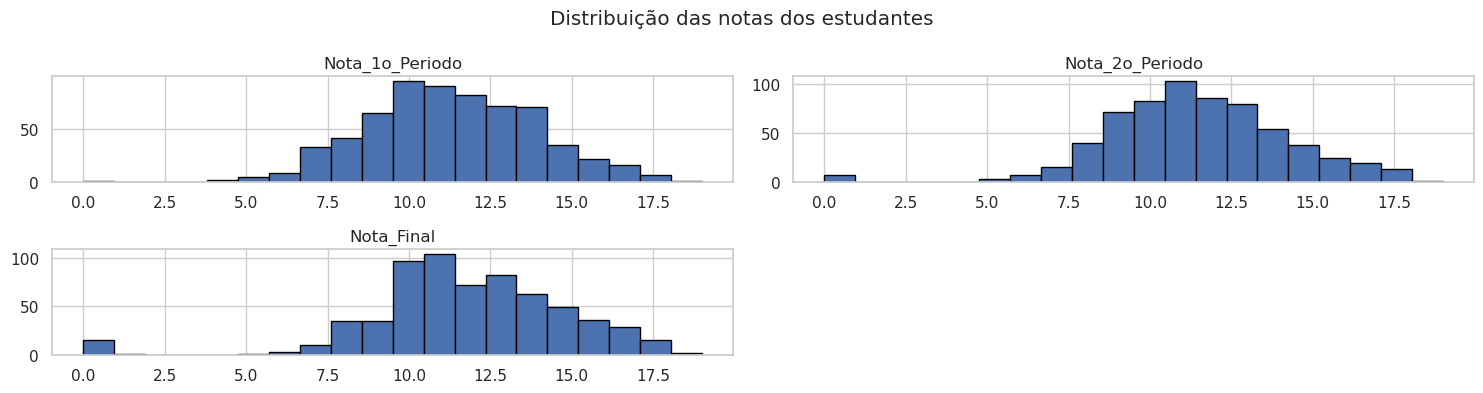

In [169]:
df[colunas_notas].hist(bins=20, figsize=(15,4), edgecolor="black")
plt.suptitle("Distribuição das notas dos estudantes")
plt.tight_layout(); plt.show()


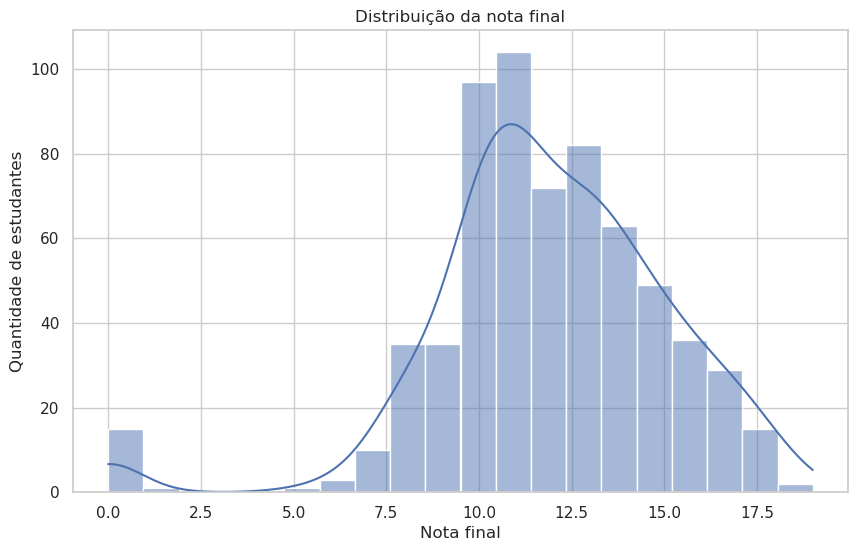

In [170]:
sns.histplot(data=df, x="Nota_Final", bins=20, kde=True)
plt.title("Distribuição da nota final"); plt.xlabel("Nota final"); plt.ylabel("Quantidade de estudantes"); plt.show()


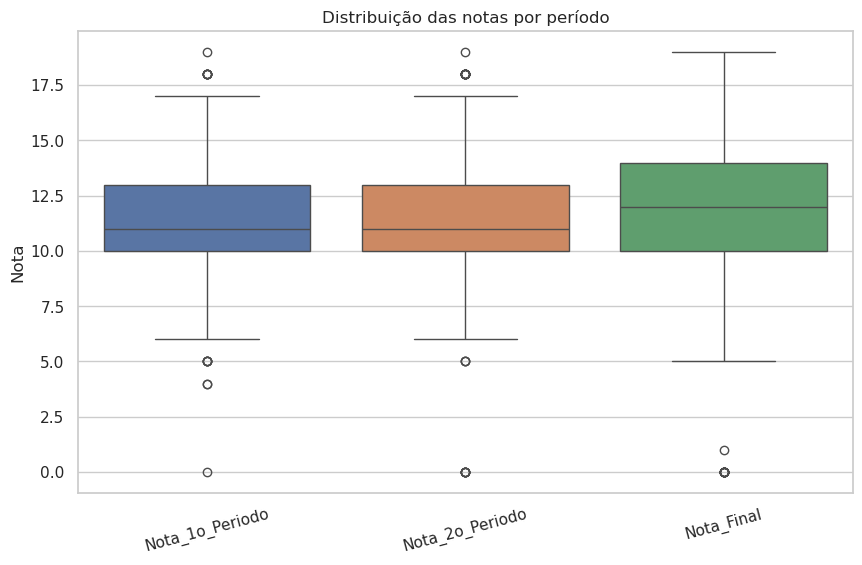

In [171]:
sns.boxplot(data=df[colunas_notas])
plt.title("Distribuição das notas por período"); plt.ylabel("Nota"); plt.xticks(rotation=15); plt.show()


**Conclusão sobre os gráficos de distribuição das notas (2.11):** Os histogramas e boxplots revelam que as notas do 1º período (média 11,40; mediana 11,0), 2º período (média 11,57; mediana 11,0) e Nota Final (média 11,91; mediana 12,0) possuem distribuição aproximadamente simétrica em torno de 11 a 12 pontos, mas apresentam uma cauda inferior com valores iguais a zero, que investigamos a seguir.

### Notas iguais a zero

Serão apenas contabilizadas e observadas. Não serão recalculadas ou removidas automaticamente.

In [172]:
pd.DataFrame({
    "Quantidade_Zero": (df[colunas_notas] == 0).sum(),
    "Percentual_Zero": ((df[colunas_notas] == 0).mean()*100).round(2)
})


,Quantidade_Zero,Percentual_Zero
Nota_1o_Periodo,1,0.15
Nota_2o_Periodo,7,1.08
Nota_Final,15,2.31


In [173]:
df[df["Nota_Final"] == 0][["Escola","Sexo","Idade","Numero_de_Faltas","Nota_1o_Periodo","Nota_2o_Periodo","Nota_Final"]]


,Escola,Sexo,Idade,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
163,GP,Masculino,18,0,11,9,0
440,MS,Masculino,16,0,7,0,0
519,MS,Masculino,16,0,8,7,0
563,MS,Masculino,17,0,7,0,0
567,MS,Masculino,18,0,4,0,0
583,MS,Feminino,18,0,8,6,0
586,MS,Feminino,17,0,8,8,0
597,MS,Feminino,18,0,9,0,0
603,MS,Feminino,18,0,5,0,0
605,MS,Feminino,19,0,5,0,0


## 2.12 Faltas e outliers

Usamos histograma, boxplot e IQR. Um outlier estatístico não é automaticamente um erro.


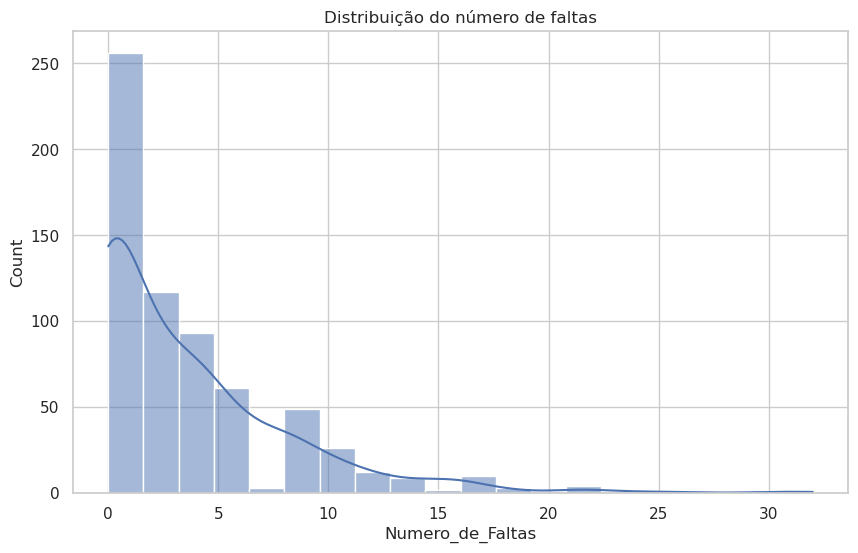

In [174]:
sns.histplot(data=df, x="Numero_de_Faltas", bins=20, kde=True)
plt.title("Distribuição do número de faltas"); plt.show()


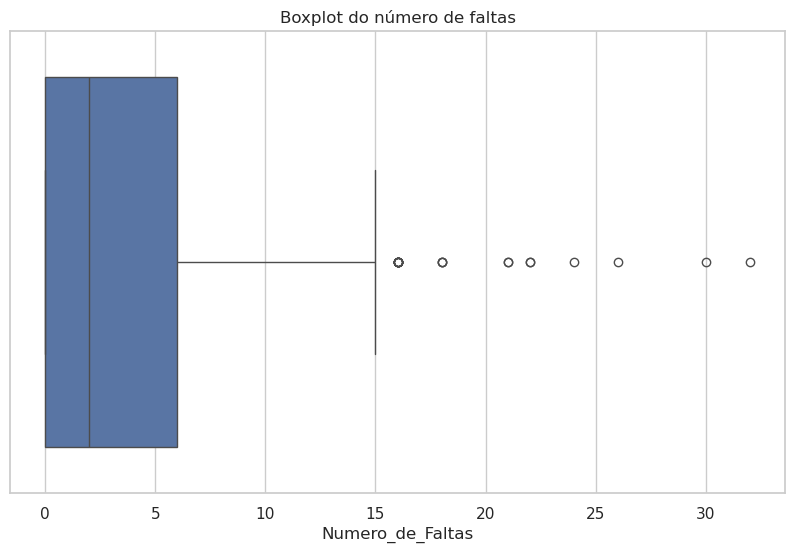

In [175]:
sns.boxplot(data=df, x="Numero_de_Faltas")
plt.title("Boxplot do número de faltas"); plt.show()


In [176]:
Q1 = df["Numero_de_Faltas"].quantile(.25); Q3 = df["Numero_de_Faltas"].quantile(.75); IQR = Q3-Q1
limite_inferior = Q1 - 1.5*IQR; limite_superior = Q3 + 1.5*IQR
faltas_atipicas = df[(df["Numero_de_Faltas"] < limite_inferior) | (df["Numero_de_Faltas"] > limite_superior)]
print("Q1:",Q1,"Q3:",Q3,"IQR:",IQR,"Limite superior:",limite_superior)
print("Casos atípicos:", faltas_atipicas.shape[0])
faltas_atipicas[["Numero_de_Faltas","Nota_Final"]].sort_values("Numero_de_Faltas",ascending=False).head(20)


Q1: 0.0 Q3: 6.0 IQR: 6.0 Limite superior: 15.0
Casos atípicos: 21


,Numero_de_Faltas,Nota_Final
197,32,14
212,30,16
256,26,8
150,24,9
155,22,6
325,22,10
413,21,10
217,21,13
397,18,14
326,18,13


**Conclusão sobre a análise de faltas e outliers (2.12):** A distribuição de `Numero_de_Faltas` tem forte assimetria positiva (mediana = 2,0 faltas, 75% dos alunos têm até 6 faltas, mas o máximo chega a 32 faltas). Pelo critério do IQR (limite superior = 15 faltas), há 21 casos atípicos. Como até 32 faltas anuais é um valor real no contexto escolar, mantemos os registros e justificamos o uso de padronização (`StandardScaler`) nos modelos sensíveis à escala.

## 2.13 Tempo de estudo e reprovações anteriores

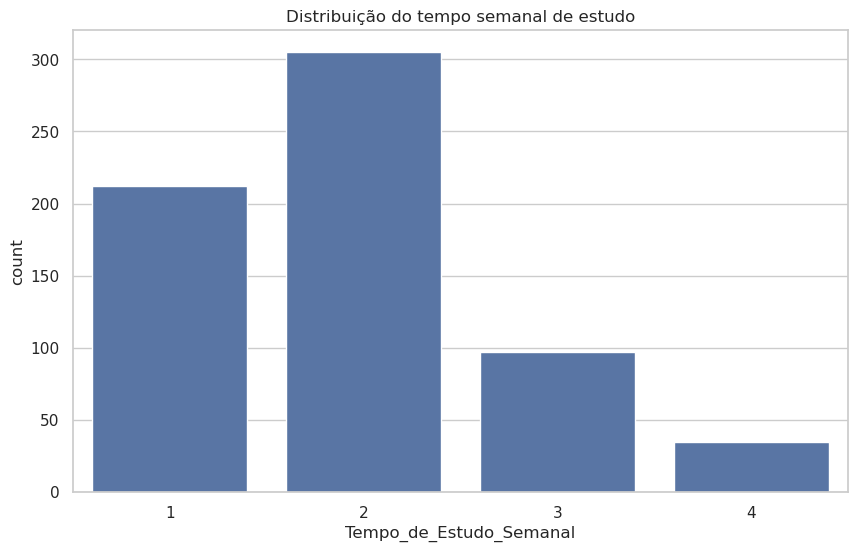

In [177]:
sns.countplot(data=df, x="Tempo_de_Estudo_Semanal", order=[1,2,3,4])
plt.title("Distribuição do tempo semanal de estudo"); plt.show()


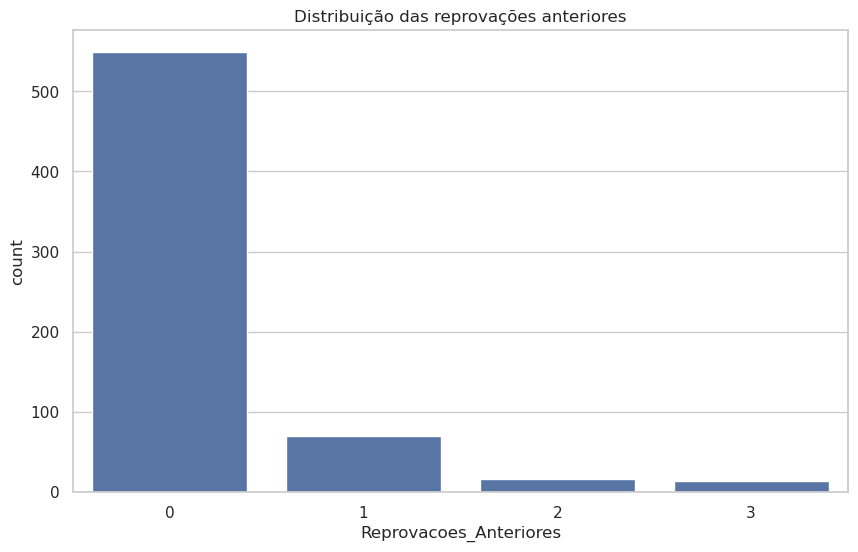

In [178]:
sns.countplot(data=df, x="Reprovacoes_Anteriores")
plt.title("Distribuição das reprovações anteriores"); plt.show()


**Conclusão sobre os gráficos de tempo de estudo e reprovações (2.13):** A maioria dos estudantes estuda de 2 a 5 horas semanais (nível 2: 305 alunos) ou menos de 2 horas (nível 1: 212 alunos), e 84,6% nunca reprovaram anteriormente (549 alunos com 0 reprovações), contra 100 alunos que possuem de 1 a 3 reprovações no histórico.

## 2.14 Relações com o desempenho

Comparamos a nota final com tempo de estudo, reprovações, faltas e algumas variáveis categóricas.

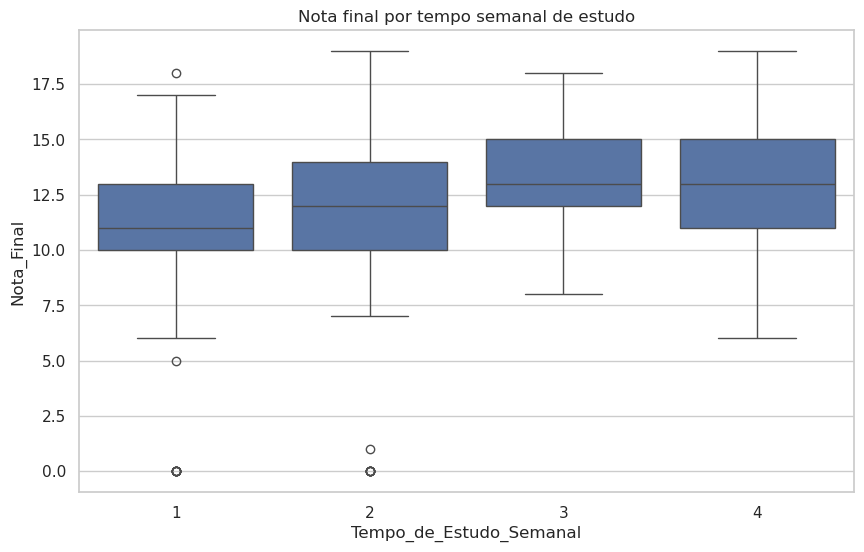

,count,mean,median,std
Tempo_de_Estudo_Semanal,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


In [179]:
sns.boxplot(data=df, x="Tempo_de_Estudo_Semanal", y="Nota_Final", order=[1,2,3,4]); plt.title("Nota final por tempo semanal de estudo"); plt.show()
df.groupby("Tempo_de_Estudo_Semanal")["Nota_Final"].agg(["count","mean","median","std"]).round(2)


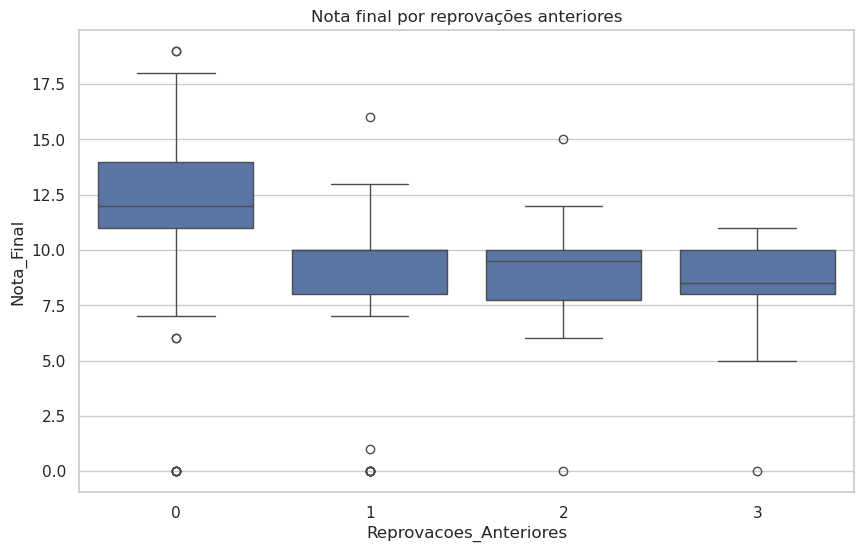

,count,mean,median,std
Reprovacoes_Anteriores,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


In [180]:
sns.boxplot(data=df, x="Reprovacoes_Anteriores", y="Nota_Final"); plt.title("Nota final por reprovações anteriores"); plt.show()
df.groupby("Reprovacoes_Anteriores")["Nota_Final"].agg(["count","mean","median","std"]).round(2)


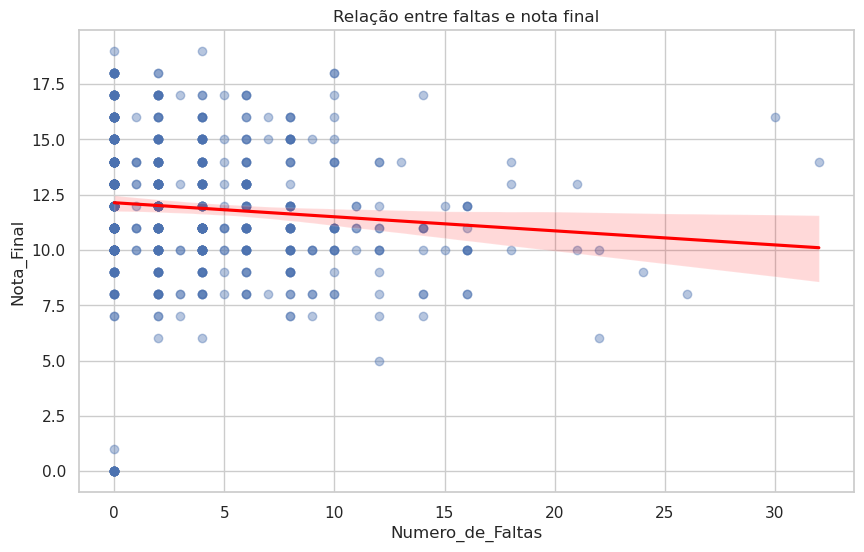

In [181]:
sns.regplot(data=df, x="Numero_de_Faltas", y="Nota_Final", scatter_kws={"alpha":.4}, line_kws={"color":"red"})
plt.title("Relação entre faltas e nota final"); plt.show()


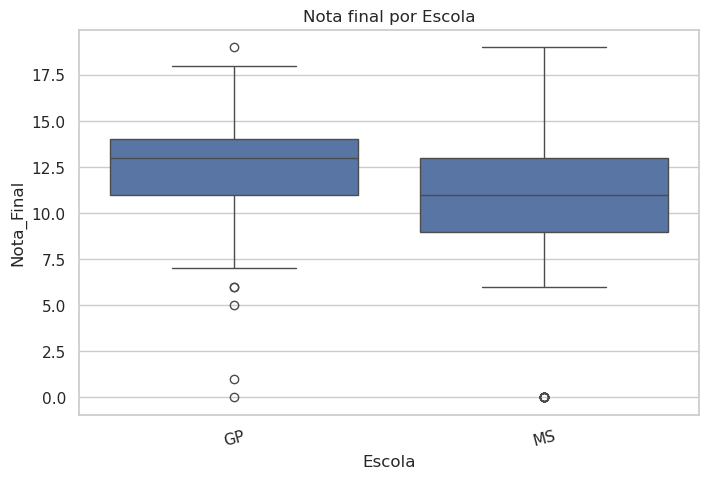

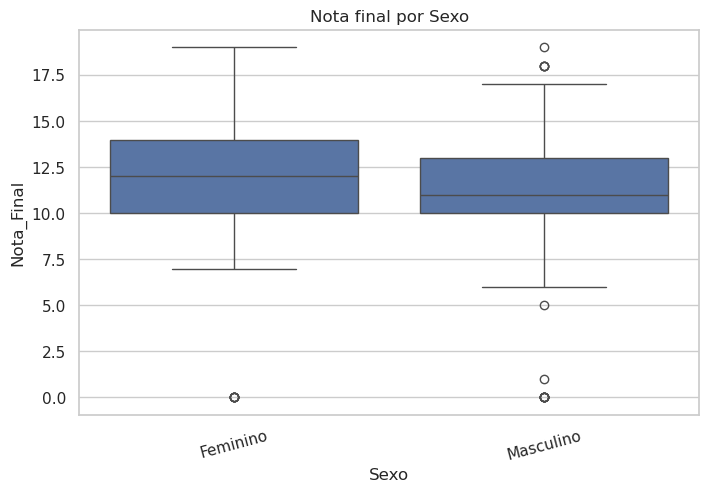

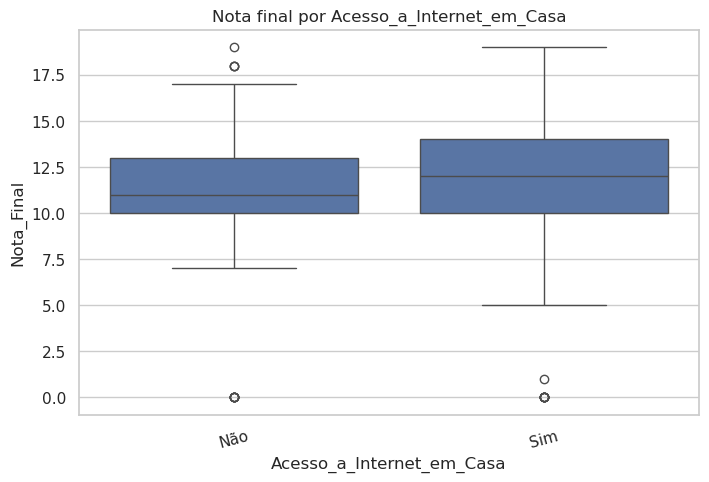

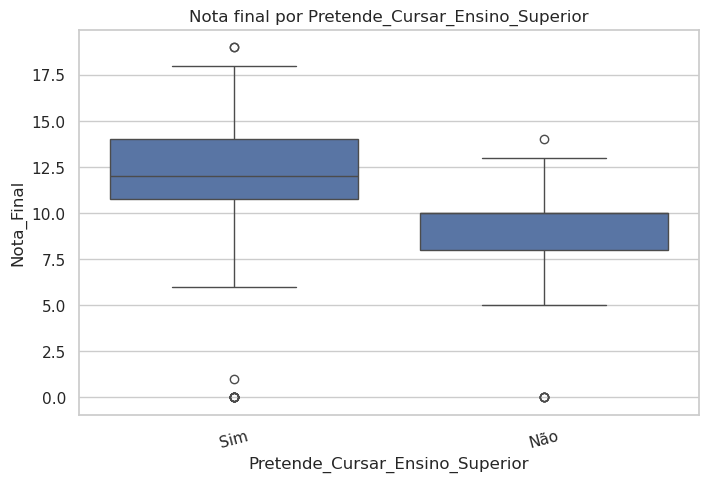

In [182]:
for coluna in ["Escola","Sexo","Acesso_a_Internet_em_Casa","Pretende_Cursar_Ensino_Superior"]:
    plt.figure(figsize=(8,5))
    sns.boxplot(data=df, x=coluna, y="Nota_Final")
    plt.title(f"Nota final por {coluna}")
    plt.xticks(rotation=15)
    plt.show()


**Conclusão sobre as relações com o desempenho (2.14):**
* **Tempo de estudo:** A nota final média sobe de 10,84 (nível 1) para 13,23 (nível 3), confirmando relação positiva.
* **Reprovações anteriores:** Alunos sem histórico de reprovação têm média 12,51 (mediana 12,0), enquanto alunos com 1 ou mais reprovações caem para a faixa de 8,07 a 8,81 pontos (abaixo da nota de corte 10).
* **Faltas e variáveis categóricas:** A linha de regressão mostra tendência negativa entre faltas e nota final ($r = -0,09$). Estudantes da escola `GP`, do sexo `Feminino`, com `Acesso a Internet em Casa` e que `Pretendem Cursar Ensino Superior` apresentam medianas superiores na nota final.

## 2.15 Correlação

A correlação mede associação linear entre as variáveis numéricas. Variáveis ordinais exigem interpretação cautelosa.

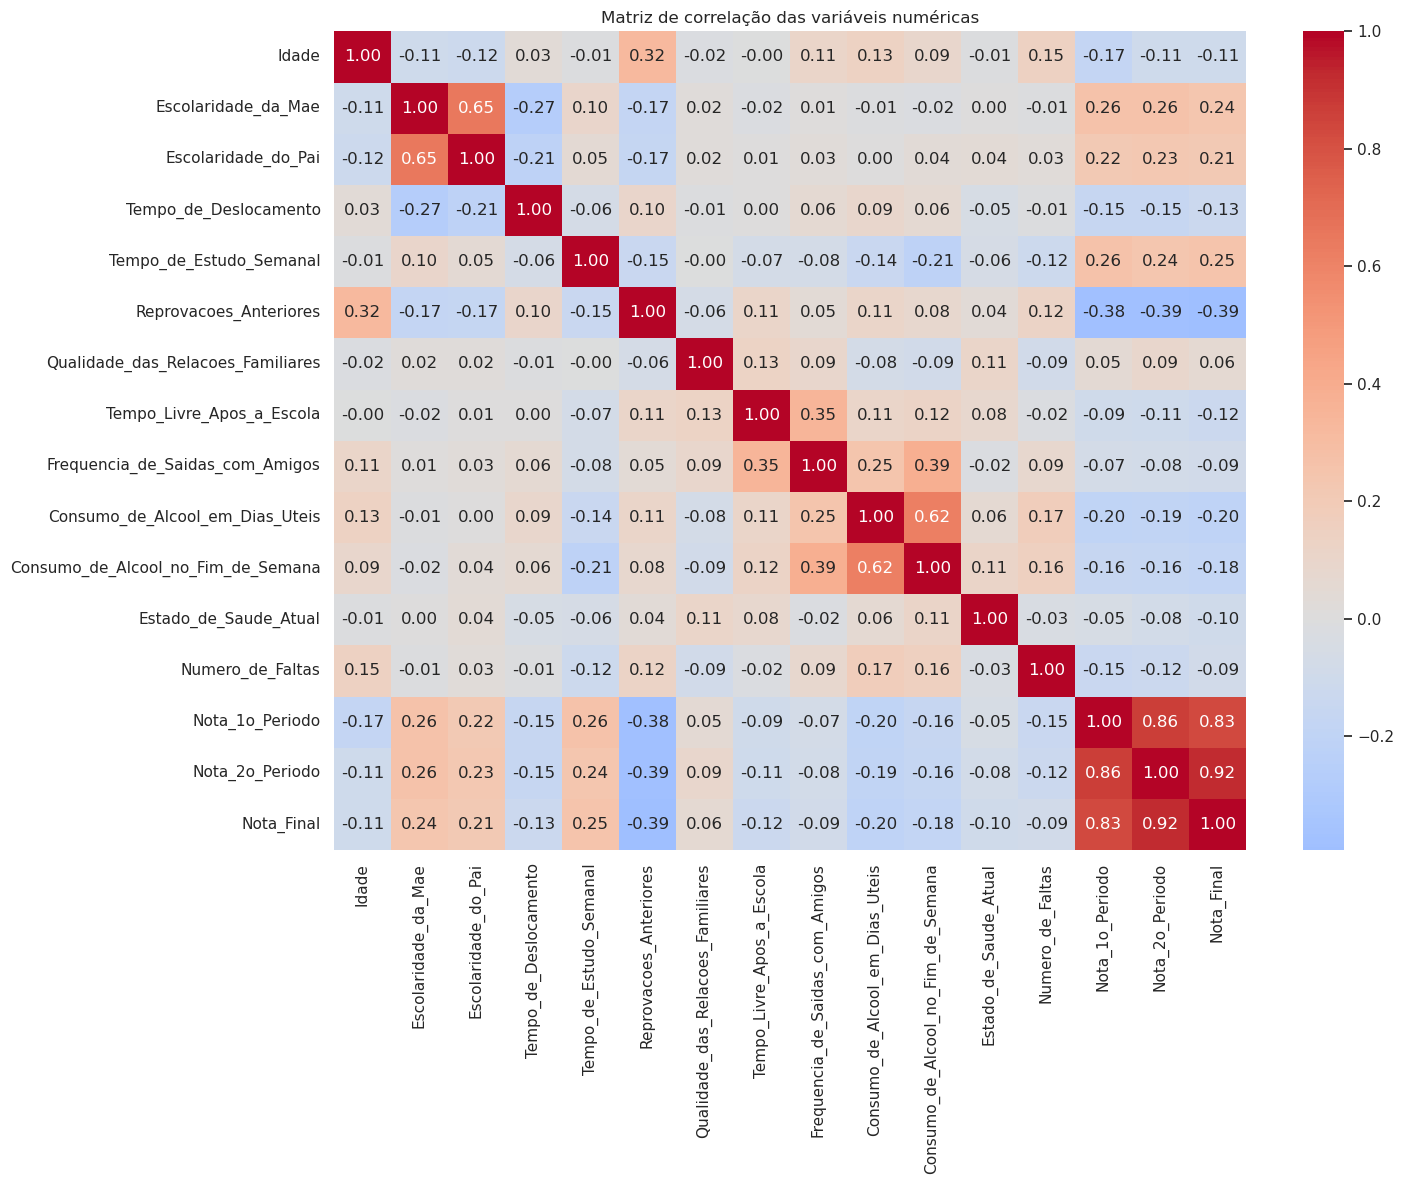

In [183]:
correlacao = df.select_dtypes(include="number").corr()
plt.figure(figsize=(15,12))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout(); plt.show()


In [184]:
correlacao_nota_final = correlacao["Nota_Final"].drop("Nota_Final").sort_values(ascending=False)
correlacao_nota_final


Nota_2o_Periodo                       0.918548
Nota_1o_Periodo                       0.826387
Tempo_de_Estudo_Semanal               0.249789
Escolaridade_da_Mae                   0.240151
Escolaridade_do_Pai                   0.211800
Qualidade_das_Relacoes_Familiares     0.063361
Frequencia_de_Saidas_com_Amigos      -0.087641
Numero_de_Faltas                     -0.091379
Estado_de_Saude_Atual                -0.098851
Idade                                -0.106505
Tempo_Livre_Apos_a_Escola            -0.122705
Tempo_de_Deslocamento                -0.127173
Consumo_de_Alcool_no_Fim_de_Semana   -0.176619
Consumo_de_Alcool_em_Dias_Uteis      -0.204719
Reprovacoes_Anteriores               -0.393316
Name: Nota_Final, dtype: float64

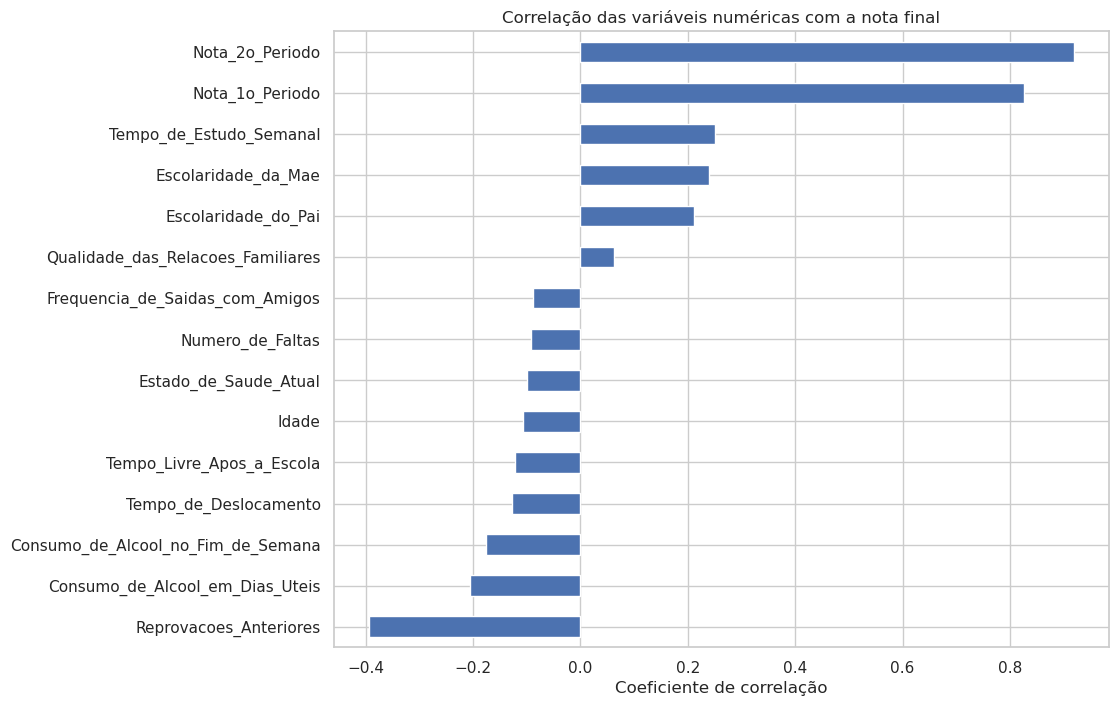

In [185]:
correlacao_nota_final.sort_values().plot(kind="barh", figsize=(10,8))
plt.title("Correlação das variáveis numéricas com a nota final"); plt.xlabel("Coeficiente de correlação"); plt.show()


**Atenção para a modelagem:** as notas do 1º e 2º períodos podem apresentar forte relação com a nota final. Se o objetivo for prever risco antes das avaliações, utilizá-las poderá causar vazamento de informação.


## 2.16 Situação final

Como análise complementar, consideramos nota final maior ou igual a 10 como aprovação.


In [186]:
df["Situacao_Final"] = np.where(df["Nota_Final"] >= 10, "Aprovado", "Reprovado")
print(df["Situacao_Final"].value_counts())
print((df["Situacao_Final"].value_counts(normalize=True)*100).round(2))


Situacao_Final
Aprovado     549
Reprovado    100
Name: count, dtype: int64
Situacao_Final
Aprovado     84.59
Reprovado    15.41
Name: proportion, dtype: float64


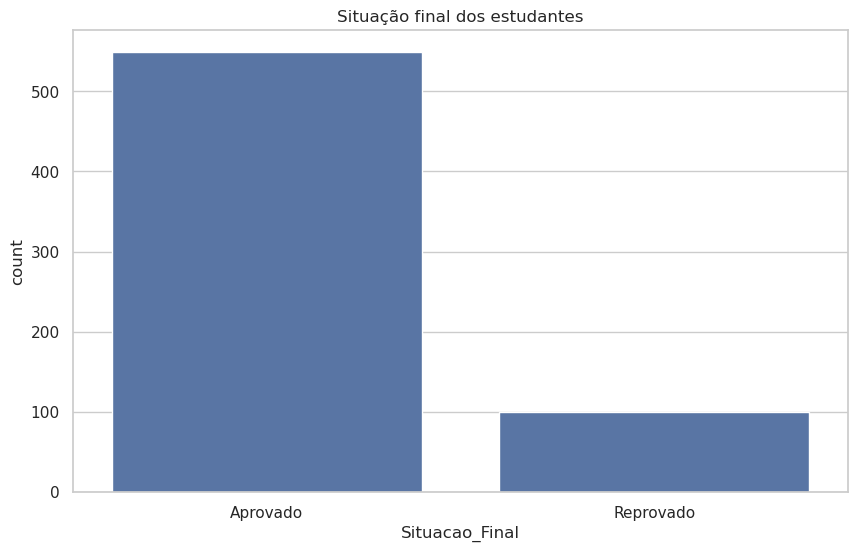

In [187]:
sns.countplot(data=df, x="Situacao_Final", order=["Aprovado","Reprovado"])
plt.title("Situação final dos estudantes"); plt.show()


### Taxa de aprovação por grupos


In [188]:
for coluna in ["Tempo_de_Estudo_Semanal","Escola","Acesso_a_Internet_em_Casa","Reprovacoes_Anteriores"]:
    print(" ", coluna)
    display(pd.crosstab(df[coluna], df["Situacao_Final"], normalize="index").mul(100).round(2))


  Tempo_de_Estudo_Semanal


Situacao_Final,Aprovado,Reprovado
Tempo_de_Estudo_Semanal,,
1,76.42,23.58
2,86.56,13.44
3,92.78,7.22
4,94.29,5.71


  Escola


Situacao_Final,Aprovado,Reprovado
Escola,,
GP,92.43,7.57
MS,69.91,30.09


  Acesso_a_Internet_em_Casa


Situacao_Final,Aprovado,Reprovado
Acesso_a_Internet_em_Casa,,
Não,78.81,21.19
Sim,86.35,13.65


  Reprovacoes_Anteriores


Situacao_Final,Aprovado,Reprovado
Reprovacoes_Anteriores,,
0,90.71,9.29
1,54.29,45.71
2,50.00,50.00
3,35.71,64.29


**Conclusão sobre a Situação Final e Taxas de Aprovação (2.16):** A base apresenta desbalanceamento de classes na situação final, com 549 aprovados (84,59%) e 100 reprovados (15,41%). A taxa de reprovação salta de 10,02% (entre quem nunca reprovou antes) para 48,57% a 64,29% (entre quem já teve reprovações anteriores), e cai de 23,58% (estudo nível 1) para 5,15% (estudo nível 3). Isso comprova que não podemos avaliar a classificação apenas pela acurácia e que o tratamento de classes desbalanceadas será essencial.

## 2.17 Codificação das variáveis categóricas

Criamos uma cópia exploratória para verificar como as categorias são transformadas em valores numéricos (mapeamento binário 0/1 e `pd.get_dummies`). Na etapa de modelagem (Etapa 4), aplicaremos a codificação dentro de um `Pipeline` após a divisão treino/teste.

In [189]:
df_modelagem = df.copy()
mapa_sim_nao = {"Não":0, "Sim":1}
colunas_sim_nao = ["Apoio_Educacional_da_Escola","Apoio_Educacional_Familiar","Aulas_Particulares_Pagas","Atividades_Extracurriculares","Frequentou_Educacao_Infantil","Pretende_Cursar_Ensino_Superior","Acesso_a_Internet_em_Casa","Relacionamento_Amoroso"]
for coluna in colunas_sim_nao:
    df_modelagem[coluna] = df_modelagem[coluna].map(mapa_sim_nao)
df_modelagem[colunas_sim_nao].isnull().sum()


Apoio_Educacional_da_Escola        0
Apoio_Educacional_Familiar         0
Aulas_Particulares_Pagas           0
Atividades_Extracurriculares       0
Frequentou_Educacao_Infantil       0
Pretende_Cursar_Ensino_Superior    0
Acesso_a_Internet_em_Casa          0
Relacionamento_Amoroso             0
dtype: int64

In [190]:
df_modelagem["Situacao_Final"] = df_modelagem["Situacao_Final"].map({"Reprovado":0,"Aprovado":1})
colunas_categoricas_restantes = df_modelagem.select_dtypes(include="object").columns.tolist()
df_codificado = pd.get_dummies(df_modelagem, columns=colunas_categoricas_restantes, drop_first=True, dtype=int)
print("Antes:", df.shape, "Depois:", df_codificado.shape)
df_codificado.head()


Antes: (649, 34) Depois: (649, 43)


,Idade,Escolaridade_da_Mae,Escolaridade_do_Pai,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final,Situacao_Final,Escola_MS,Sexo_Masculino,Tipo_de_Endereco_Urbano,Tamanho_da_Familia_Mais de 3,Situacao_dos_Pais_Separados,Ocupacao_da_Mae_Outro,Ocupacao_da_Mae_Professor(a),Ocupacao_da_Mae_Saude,Ocupacao_da_Mae_Servicos,Ocupacao_do_Pai_Outro,Ocupacao_do_Pai_Professor(a),Ocupacao_do_Pai_Saude,Ocupacao_do_Pai_Servicos,Motivo_da_Escolha_da_Escola_Preferencia pelo curso,Motivo_da_Escolha_da_Escola_Proximidade de casa,Motivo_da_Escolha_da_Escola_Reputacao da escola,Responsavel_Outro,Responsavel_Pai
0,18,4,4,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,4,0,11,11,1,0,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0
1,17,1,1,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,2,9,11,11,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1
2,15,1,1,1,2,0,1,0,0,0,1,1,1,0,4,3,2,2,3,3,6,12,13,12,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,15,4,2,1,3,0,0,1,0,1,1,1,1,1,3,2,2,1,1,5,0,14,14,14,1,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0
4,16,3,3,1,2,0,0,1,0,0,1,1,0,0,4,3,2,1,2,5,0,11,13,13,1,0,0,1,1,0,1,0,0,0,1,0,0,0,0,1,0,0,1


## 2.18 Padronização

A padronização é útil para modelos sensíveis à escala. Na modelagem definitiva, o `StandardScaler` deve ser ajustado somente nos dados de treino.


In [191]:

df_padronizado = df_codificado.copy()
colunas_para_padronizar = ["Idade","Numero_de_Faltas"]
scaler = StandardScaler()
df_padronizado[colunas_para_padronizar] = scaler.fit_transform(df_padronizado[colunas_para_padronizar])
df_padronizado[colunas_para_padronizar].describe().round(2)


,Idade,Numero_de_Faltas
count,649.00,649.00
mean,-0.00,0.00
std,1.00,1.00
min,-1.43,-0.79
25%,-0.61,-0.79
50%,0.21,-0.36
75%,1.03,0.50
max,4.32,6.11


## 2.19 Resumo da qualidade da base


In [192]:
resumo_qualidade = pd.DataFrame({
    "Indicador":["Quantidade de estudantes","Variáveis originais","Valores ausentes","Linhas duplicadas","Menor nota final","Maior nota final","Maior número de faltas"],
    "Resultado":[df.shape[0],33,df.isnull().sum().sum(),df.duplicated().sum(),df["Nota_Final"].min(),df["Nota_Final"].max(),df["Numero_de_Faltas"].max()]
})
resumo_qualidade


,Indicador,Resultado
0,Quantidade de estudantes,649
1,Variáveis originais,33
2,Valores ausentes,0
3,Linhas duplicadas,0
4,Menor nota final,0
5,Maior nota final,19
6,Maior número de faltas,32


## 2.20 Salvamento das bases processadas

Os resultados são salvos em novos arquivos, preservando o CSV original.


In [193]:
df.to_csv("estudantes_desempenho_tratado.csv", sep=";", index=False, encoding="utf-8-sig")
df_codificado.to_csv("estudantes_desempenho_codificado.csv", sep=";", index=False, encoding="utf-8-sig")
df_padronizado.to_csv("estudantes_desempenho_padronizado.csv", sep=";", index=False, encoding="utf-8-sig")


# Conclusão da Etapa 2 e Como a EDA Guia a Modelagem

Foram examinados tipos, ausências, duplicidades, categorias, intervalos esperados e distribuições. Também foram analisadas as relações entre notas, faltas, tempo de estudo, reprovações e desempenho escolar.

**Síntese das decisões guiadas pela EDA para as próximas etapas:**
1. **Valores ausentes e duplicidades:** Como a base possui 0 valores ausentes e 0 duplicatas, não há necessidade de imputação ou exclusão de linhas.
2. **Notas iguais a zero e Outliers:** Notas iguais a zero (15 casos na nota final) e valores elevados em faltas (21 casos acima de 15 faltas) foram preservados como ocorrências reais do contexto escolar.
3. **Escala e Codificação sem Vazamento:** Devido à diferença de amplitude entre variáveis (ex.: `Numero_de_Faltas` de 0 a 32 vs. escalas de 1 a 5), utilizaremos `StandardScaler` e `OneHotEncoder` ajustados exclusivamente no conjunto de treino após o `train_test_split`.
4. **Cuidado com Vazamento Temporal (`Nota_1o_Periodo` e `Nota_2o_Periodo`):** Dada a forte correlação das notas parciais ($r = 0,83$ e $r = 0,92$) com a `Nota_Final`, dividiremos a modelagem em **Cenário A (Início do Ano Letivo — Sem Notas Parciais)** e **Cenário B (Após o 2º Período — Com Notas Parciais)**.
5. **Classes Desbalanceadas (84,59% Aprovados vs. 15,41% Reprovados):** Na classificação, utilizaremos `class_weight="balanced"` e priorizaremos **Recall** e **F1-Score** da classe minoritária (Reprovados).

---

# Etapa 3: Definição da Tarefa

> **Enunciado da Especificação (Etapa 3):** *"3. Definição da tarefa: supervisionada ou não supervisionada; se supervisionada, regressão ou classificação."*

Para contemplar os fundamentos de aprendizado supervisionado e não supervisionado da disciplina, definimos três tarefas sobre a base:
1. **Aprendizado Supervisionado — Regressão:**
   * **Alvo ($y$):** `Nota_Final` (variável numérica de 0 a 20 pontos).
   * **Métricas de Avaliação:** Erro Médio Absoluto (**MAE**, lido diretamente em pontos na nota), Raiz do Erro Quadrático Médio (**RMSE**) e Coeficiente de Determinação (**$R^2$**).
2. **Aprendizado Supervisionado — Classificação:**
   * **Alvo ($y$):** `Risco_Reprovacao` (`1` = Reprovado com `Nota_Final < 10`; `0` = Aprovado com `Nota_Final >= 10`).
   * **Métricas de Avaliação:** Como a classe `1` (Reprovado) representa apenas **15,41%** da base (100 em 649 alunos), a acurácia isolada é enganosa. Avaliamos os modelos pelo **Recall (Sensibilidade)** da classe `1` (percentual de alunos em risco que o modelo consegue encontrar), **Precisão**, **F1-Score** e **Matriz de Confusão**.
3. **Aprendizado Não Supervisionado — Clusterização e Redução de Dimensionalidade:**
   * **Algoritmos:** **K-Means** para segmentação de perfis comportamentais/familiares e **PCA** (*Principal Component Analysis*) para visualização bidimensional, avaliados por **Inércia (WCSS)** e **Silhouette Score**.

### 3.1 Divisão Treino e Teste Antes do Pré-processamento (Prevenção de Vazamento)
Seguindo as boas práticas, partimos do dataframe `df` limpo (antes da codificação da seção 2.17) e realizamos a separação **80% treino (519 alunos) e 20% teste (130 alunos)** estratificada pelo alvo **antes** de ajustar qualquer escalonador ou codificador.

In [194]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Alvo binário para classificação: 1 = Reprovado (Nota_Final < 10), 0 = Aprovado (Nota_Final >= 10)
df["Risco_Reprovacao"] = np.where(df["Nota_Final"] < 10, 1, 0)

colunas_alvo = ["Nota_Final", "Situacao_Final", "Risco_Reprovacao"]

# Cenário A: Variáveis disponíveis no início do ano (sem notas do 1º e 2º períodos)
features_cenario_a = [c for c in df.columns if c not in colunas_alvo + ["Nota_1o_Periodo", "Nota_2o_Periodo"]]
num_cenario_a = df[features_cenario_a].select_dtypes(include="number").columns.tolist()
cat_cenario_a = df[features_cenario_a].select_dtypes(include="object").columns.tolist()

# Cenário B: Variáveis disponíveis após o 2º período (com notas do 1º e 2º períodos)
features_cenario_b = [c for c in df.columns if c not in colunas_alvo]
num_cenario_b = df[features_cenario_b].select_dtypes(include="number").columns.tolist()
cat_cenario_b = df[features_cenario_b].select_dtypes(include="object").columns.tolist()

# Separação Treino (80%) e Teste (20%) estratificada ANTES de qualquer pré-processamento
idx_treino, idx_teste = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df["Risco_Reprovacao"]
)

print(f"Estudantes no Treino: {len(idx_treino)} | Estudantes no Teste: {len(idx_teste)}")
print("Proporção Risco_Reprovacao no Treino (%):")
print((df.loc[idx_treino, "Risco_Reprovacao"].value_counts(normalize=True) * 100).round(2))
print("\nProporção Risco_Reprovacao no Teste (%):")
print((df.loc[idx_teste, "Risco_Reprovacao"].value_counts(normalize=True) * 100).round(2))

Estudantes no Treino: 519 | Estudantes no Teste: 130
Proporção Risco_Reprovacao no Treino (%):
Risco_Reprovacao
0    84.59
1    15.41
Name: proportion, dtype: float64

Proporção Risco_Reprovacao no Teste (%):
Risco_Reprovacao
0    84.62
1    15.38
Name: proportion, dtype: float64


---

# Etapa 4 e Etapa 5: Construção do Modelo e Avaliação

> **Enunciado da Especificação (Etapa 4):** *"4. Construção do modelo: algoritmos adequados ao problema, sempre comparados com uma referência simples (por exemplo, prever a média ou a classe mais comum)."*  
> **Enunciado da Especificação (Etapa 5):** *"5. Avaliação: métricas apropriadas ao problema, lidas na unidade do negócio ("erramos em média 2,5 anos", "encontramos 70% dos clientes que cancelam")."*

## 4.1 Modelagem e Avaliação — Regressão (`Nota_Final`)
Comparamos 5 modelos ajustados via `Pipeline` (escalonamento `StandardScaler` e codificação `OneHotEncoder` aprendidos apenas no treino):
* **Referência Simples (`DummyRegressor`):** Prevê sempre a média das notas do treino.
* **Regressão Linear (`LinearRegression`):** Modelo linear sem regularização.
* **Ridge (`Ridge`):** Regressão linear com regularização L2 (alpha = 10).
* **Lasso (`Lasso`):** Regressão linear com regularização L1 (alpha = 0,1), que seleciona variáveis zerando coeficientes fracos.
* **Random Forest (`RandomForestRegressor`):** Comitê de árvores de decisão com profundidade limitada (`max_depth=5`) para conter *overfitting*.

In [195]:
def treinar_avaliar_regressao(features, cols_num, cols_cat, nome_cenario):
    X_train = df.loc[idx_treino, features]
    X_test = df.loc[idx_teste, features]
    y_train = df.loc[idx_treino, "Nota_Final"]
    y_test = df.loc[idx_teste, "Nota_Final"]
    
    preprocessador = ColumnTransformer(transformers=[
        ("num", StandardScaler(), cols_num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cols_cat)
    ])
    
    modelos = {
        "Referência (Dummy - Média)": DummyRegressor(strategy="mean"),
        "Regressão Linear": LinearRegression(),
        "Ridge (L2, alpha=10)": Ridge(alpha=10.0, random_state=42),
        "Lasso (L1, alpha=0.1)": Lasso(alpha=0.1, random_state=42),
        "Random Forest (max_depth=5)": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
    }
    
    linhas = []
    for nome, mod in modelos.items():
        pipe = Pipeline(steps=[("prep", preprocessador), ("modelo", mod)])
        pipe.fit(X_train, y_train)
        
        p_treino = pipe.predict(X_train)
        p_teste = pipe.predict(X_test)
        
        linhas.append({
            "Cenário": nome_cenario,
            "Modelo": nome,
            "MAE Treino (pontos)": round(mean_absolute_error(y_train, p_treino), 2),
            "MAE Teste (pontos)": round(mean_absolute_error(y_test, p_teste), 2),
            "RMSE Teste (pontos)": round(np.sqrt(mean_squared_error(y_test, p_teste)), 2),
            "R² Treino": round(r2_score(y_train, p_treino), 3),
            "R² Teste": round(r2_score(y_test, p_teste), 3)
        })
    return pd.DataFrame(linhas)

res_reg_a = treinar_avaliar_regressao(features_cenario_a, num_cenario_a, cat_cenario_a, "Cenário A (Sem Notas 1º/2º Per.)")
res_reg_b = treinar_avaliar_regressao(features_cenario_b, num_cenario_b, cat_cenario_b, "Cenário B (Com Notas 1º/2º Per.)")

print("Resultados de Regressão - Cenário A (Início do Ano):")
display(res_reg_a)
print("\nResultados de Regressão - Cenário B (Com Notas Parciais):")
display(res_reg_b)

Resultados de Regressão - Cenário A (Início do Ano):


,Cenário,Modelo,MAE Treino (pontos),MAE Teste (pontos),RMSE Teste (pontos),R² Treino,R² Teste
0,Cenário A (Sem Notas 1º/2º Per.),Referência (Dummy - Média),2.36,2.60,3.56,0.000,-0.000
1,Cenário A (Sem Notas 1º/2º Per.),Regressão Linear,1.82,2.21,3.11,0.382,0.237
2,Cenário A (Sem Notas 1º/2º Per.),"Ridge (L2, alpha=10)",1.81,2.20,3.10,0.379,0.241
3,Cenário A (Sem Notas 1º/2º Per.),"Lasso (L1, alpha=0.1)",1.90,2.27,3.18,0.321,0.205
4,Cenário A (Sem Notas 1º/2º Per.),Random Forest (max_depth=5),1.59,2.22,3.12,0.572,0.234



Resultados de Regressão - Cenário B (Com Notas Parciais):


,Cenário,Modelo,MAE Treino (pontos),MAE Teste (pontos),RMSE Teste (pontos),R² Treino,R² Teste
0,Cenário B (Com Notas 1º/2º Per.),Referência (Dummy - Média),2.36,2.60,3.56,0.000,-0.000
1,Cenário B (Com Notas 1º/2º Per.),Regressão Linear,0.76,0.85,1.47,0.866,0.831
2,Cenário B (Com Notas 1º/2º Per.),"Ridge (L2, alpha=10)",0.76,0.84,1.47,0.864,0.829
3,Cenário B (Com Notas 1º/2º Per.),"Lasso (L1, alpha=0.1)",0.76,0.81,1.43,0.851,0.838
4,Cenário B (Com Notas 1º/2º Per.),Random Forest (max_depth=5),0.58,0.94,1.57,0.934,0.806


/tmp/ipykernel_13442/1810421351.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_reg_a, x="MAE Teste (pontos)", y="Modelo", ax=axes[0], palette="Blues_r")
/tmp/ipykernel_13442/1810421351.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_reg_b, x="MAE Teste (pontos)", y="Modelo", ax=axes[1], palette="Greens_r")


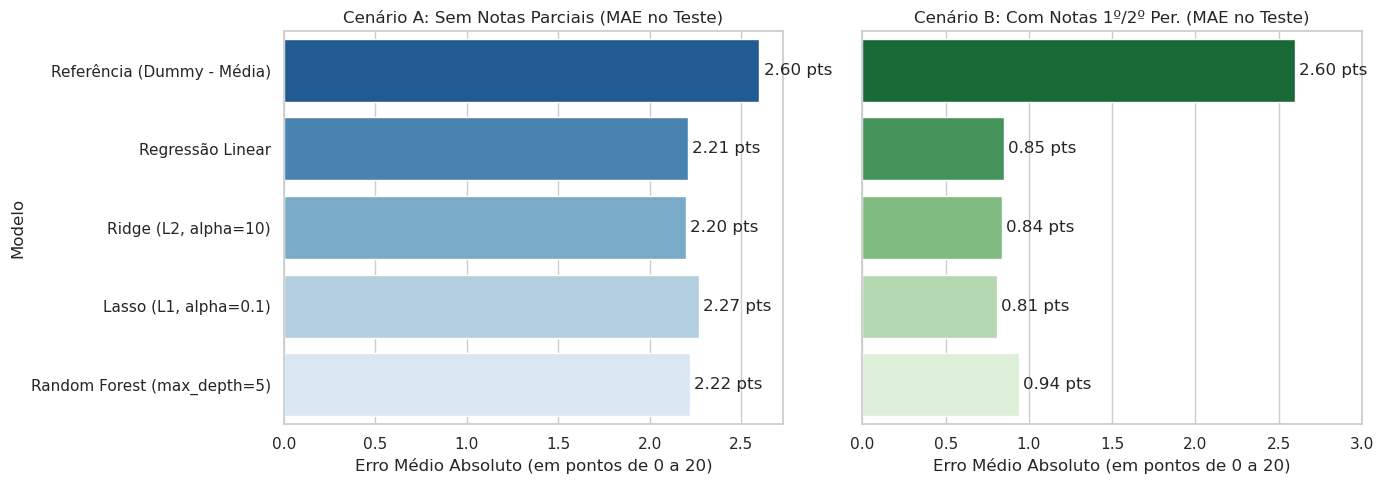

In [196]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.barplot(data=res_reg_a, x="MAE Teste (pontos)", y="Modelo", ax=axes[0], palette="Blues_r")
axes[0].set_title("Cenário A: Sem Notas Parciais (MAE no Teste)")
axes[0].set_xlabel("Erro Médio Absoluto (em pontos de 0 a 20)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f pts", padding=3)

sns.barplot(data=res_reg_b, x="MAE Teste (pontos)", y="Modelo", ax=axes[1], palette="Greens_r")
axes[1].set_title("Cenário B: Com Notas 1º/2º Per. (MAE no Teste)")
axes[1].set_xlabel("Erro Médio Absoluto (em pontos de 0 a 20)")
axes[1].set_ylabel("")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.2f pts", padding=3)

plt.xlim(0, 3.0)
plt.tight_layout()
plt.show()

**Leitura das métricas de Regressão na unidade do problema:**
* **Referência Simples (`DummyRegressor`):** Prever a nota média da escola gera um erro médio de **2,60 pontos** no teste ($R^2 = 0,000$).
* **Cenário A (Alerta Precoce no início do ano):** O modelo **Ridge (L2)** obteve o melhor resultado no teste: **erramos em média 2,20 pontos na escala de 0 a 20** ($R^2 = 0,241$), superando a referência simples em 0,40 ponto por estudante apenas com informações demográficas e de histórico. O Random Forest apresentou menor erro no treino (1,59 ponto), mas erro maior no teste (2,22 pontos), evidenciando que o modelo linear regularizado (Ridge) controlou melhor o *overfitting*.
* **Cenário B (Com Notas do 1º e 2º Períodos):** O modelo **Lasso (L1)** teve o melhor desempenho: **erramos em média apenas 0,81 ponto na nota final** ($R^2 = 0,838$), reduzindo o erro da referência simples de 2,60 para 0,81 ponto.

## 4.2 Modelagem e Avaliação — Classificação (`Risco_Reprovacao`)
Comparamos a referência simples (`DummyClassifier`) com a **Regressão Logística** (sem e com balanceamento de classes + regularização L2) e o **Random Forest Classifier** balanceado.

In [197]:
def treinar_avaliar_classificacao(features, cols_num, cols_cat, nome_cenario):
    X_train = df.loc[idx_treino, features]
    X_test = df.loc[idx_teste, features]
    y_train = df.loc[idx_treino, "Risco_Reprovacao"]
    y_test = df.loc[idx_teste, "Risco_Reprovacao"]
    
    preprocessador = ColumnTransformer(transformers=[
        ("num", StandardScaler(), cols_num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cols_cat)
    ])
    
    modelos = {
        "Referência (Dummy - Classe Mais Comum)": DummyClassifier(strategy="most_frequent"),
        "Reg. Logística (Sem Balanceamento)": LogisticRegression(max_iter=1000, random_state=42),
        "Reg. Logística (Balanced + L2 C=0.5)": LogisticRegression(class_weight="balanced", C=0.5, max_iter=1000, random_state=42),
        "Random Forest (Balanced, max_depth=5)": RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42)
    }
    
    linhas = []
    pipes = {}
    for nome, mod in modelos.items():
        pipe = Pipeline(steps=[("prep", preprocessador), ("modelo", mod)])
        pipe.fit(X_train, y_train)
        pipes[nome] = pipe
        
        p_treino = pipe.predict(X_train)
        p_teste = pipe.predict(X_test)
        
        linhas.append({
            "Cenário": nome_cenario,
            "Modelo": nome,
            "Acurácia Teste (%)": round(accuracy_score(y_test, p_teste) * 100, 1),
            "Precisão Teste (%)": round(precision_score(y_test, p_teste, zero_division=0) * 100, 1),
            "Recall Treino (%)": round(recall_score(y_train, p_treino, zero_division=0) * 100, 1),
            "Recall Teste (%)": round(recall_score(y_test, p_teste, zero_division=0) * 100, 1),
            "F1 Treino": round(f1_score(y_train, p_treino, zero_division=0), 3),
            "F1 Teste": round(f1_score(y_test, p_teste, zero_division=0), 3)
        })
    return pd.DataFrame(linhas), pipes, y_test

res_clf_a, pipes_a, y_teste_real = treinar_avaliar_classificacao(features_cenario_a, num_cenario_a, cat_cenario_a, "Cenário A (Sem Notas 1º/2º Per.)")
res_clf_b, pipes_b, _ = treinar_avaliar_classificacao(features_cenario_b, num_cenario_b, cat_cenario_b, "Cenário B (Com Notas 1º/2º Per.)")

print("Resultados de Classificação - Cenário A (Início do Ano):")
display(res_clf_a)
print("\nResultados de Classificação - Cenário B (Com Notas Parciais):")
display(res_clf_b)

Resultados de Classificação - Cenário A (Início do Ano):


,Cenário,Modelo,Acurácia Teste (%),Precisão Teste (%),Recall Treino (%),Recall Teste (%),F1 Treino,F1 Teste
0,Cenário A (Sem Notas 1º/2º Per.),Referência (Dummy - Classe Mais Comum),84.6,0.0,0.0,0.0,0.000,0.000
1,Cenário A (Sem Notas 1º/2º Per.),Reg. Logística (Sem Balanceamento),83.1,33.3,33.8,10.0,0.446,0.154
2,Cenário A (Sem Notas 1º/2º Per.),Reg. Logística (Balanced + L2 C=0.5),78.5,38.2,85.0,65.0,0.596,0.481
3,Cenário A (Sem Notas 1º/2º Per.),"Random Forest (Balanced, max_depth=5)",83.8,48.0,92.5,60.0,0.744,0.533



Resultados de Classificação - Cenário B (Com Notas Parciais):


,Cenário,Modelo,Acurácia Teste (%),Precisão Teste (%),Recall Treino (%),Recall Teste (%),F1 Treino,F1 Teste
0,Cenário B (Com Notas 1º/2º Per.),Referência (Dummy - Classe Mais Comum),84.6,0.0,0.0,0.0,0.000,0.000
1,Cenário B (Com Notas 1º/2º Per.),Reg. Logística (Sem Balanceamento),91.5,71.4,77.5,75.0,0.832,0.732
2,Cenário B (Com Notas 1º/2º Per.),Reg. Logística (Balanced + L2 C=0.5),90.8,64.3,100.0,90.0,0.829,0.750
3,Cenário B (Com Notas 1º/2º Per.),"Random Forest (Balanced, max_depth=5)",86.2,53.1,100.0,85.0,0.847,0.654


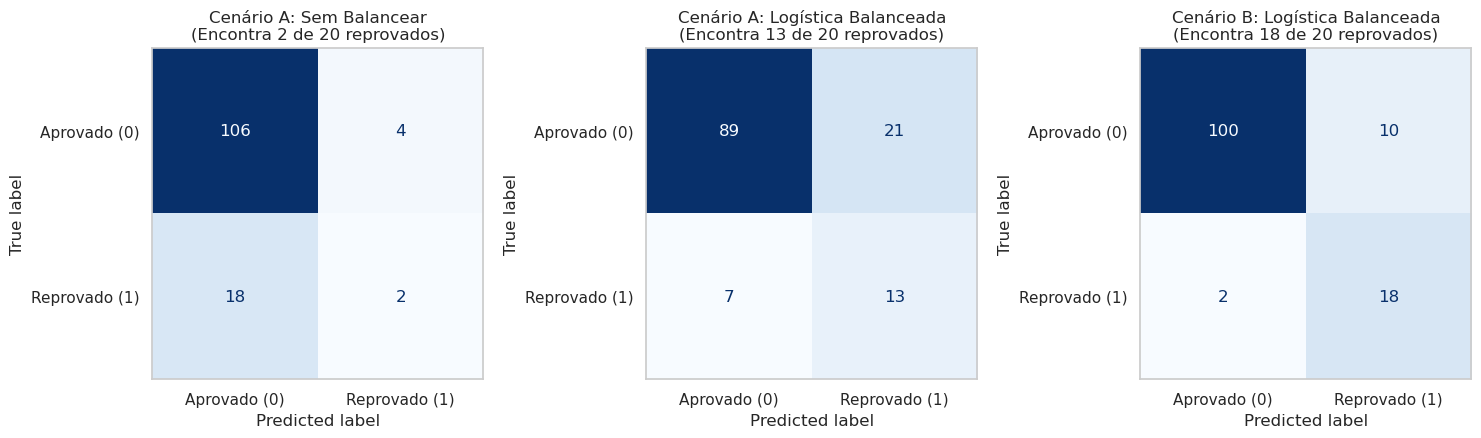

In [198]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

comparacoes = [
    ("Reg. Logística (Sem Balanceamento)", pipes_a, features_cenario_a, "Cenário A: Sem Balancear\n(Encontra 2 de 20 reprovados)"),
    ("Reg. Logística (Balanced + L2 C=0.5)", pipes_a, features_cenario_a, "Cenário A: Logística Balanceada\n(Encontra 13 de 20 reprovados)"),
    ("Reg. Logística (Balanced + L2 C=0.5)", pipes_b, features_cenario_b, "Cenário B: Logística Balanceada\n(Encontra 18 de 20 reprovados)")
]

for ax, (nome_m, dict_p, cols_f, titulo) in zip(axes, comparacoes):
    preds = dict_p[nome_m].predict(df.loc[idx_teste, cols_f])
    cm = confusion_matrix(y_teste_real, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Aprovado (0)", "Reprovado (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo)
    ax.grid(False)

plt.tight_layout()
plt.show()

**Leitura das métricas de Classificação na unidade do problema:**
* **Por que a Acurácia isolada falha:** No conjunto de teste (130 alunos, sendo 110 aprovados e 20 reprovados), a referência simples (`DummyClassifier`) obtém **84,6% de acurácia**, mas **encontra 0% dos alunos que reprovam (0 de 20)**. Sem balanceamento de classes, a Regressão Logística padrão no Cenário A encontra apenas **10% dos alunos que reprovam (2 de 20)**.
* **Impacto do Balanceamento (`class_weight="balanced"` + L2):**
  * **No Cenário A (Início do Ano):** A Regressão Logística Balanceada atinge **Recall de 65,0% no teste (F1 = 0,481)** — ou seja, **encontramos 65% dos estudantes que iriam reprovar (13 de 20 alunos) logo no início do ano letivo**, antes de qualquer prova.
  * **No Cenário B (Após o 2º Período):** A Regressão Logística Balanceada alcança **Recall de 90,0% (F1 = 0,750 e Acurácia = 90,8%)**, **encontrando 18 dos 20 estudantes em risco de reprovação** a tempo da recuperação final.

## 4.3 Modelagem Não Supervisionada — Clusterização (K-Means) e PCA
Aplicamos o **K-Means** e a redução de dimensionalidade com **PCA** nas 13 variáveis numéricas/ordinais socioeconômicas e comportamentais (sem incluir as notas no treinamento do agrupamento).

,Número de Clusters (k),Inércia (WCSS),Silhouette Score
0,2,7457.7,0.147
1,3,6795.9,0.102
2,4,6379.6,0.105
3,5,6099.4,0.090
4,6,5886.0,0.090


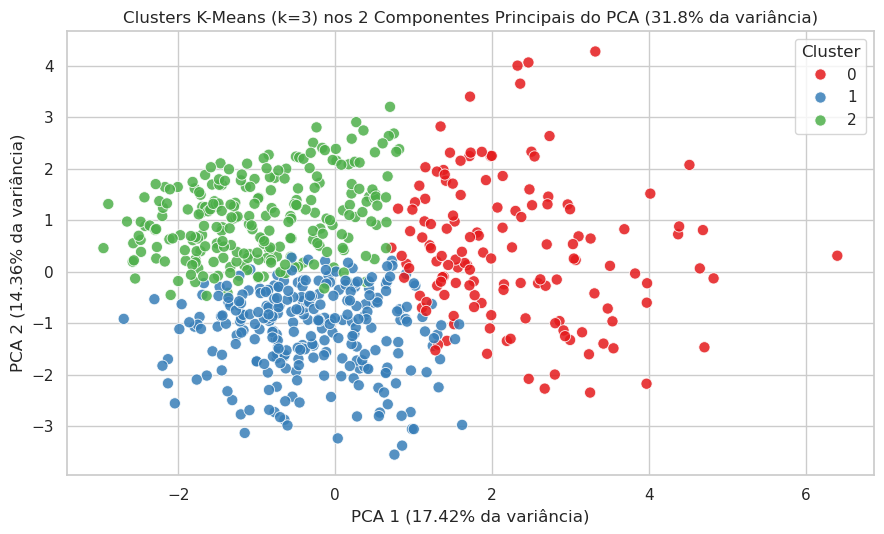

,Idade,Escolaridade_da_Mae,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Consumo_de_Alcool_no_Fim_de_Semana,Numero_de_Faltas,Nota_Final,Quantidade_Alunos,Taxa_Reprovacao (%)
Cluster,,,,,,,,,
0,17.25,2.21,1.58,0.64,3.75,6.50,9.96,139,33.0
1,16.68,1.74,1.96,0.18,1.75,2.88,11.72,268,15.0
2,16.53,3.55,2.10,0.03,2.03,2.89,13.23,242,6.0


In [199]:
colunas_cluster = [
    "Idade", "Escolaridade_da_Mae", "Escolaridade_do_Pai",
    "Tempo_de_Deslocamento", "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores",
    "Qualidade_das_Relacoes_Familiares", "Tempo_Livre_Apos_a_Escola",
    "Frequencia_de_Saidas_com_Amigos", "Consumo_de_Alcool_em_Dias_Uteis",
    "Consumo_de_Alcool_no_Fim_de_Semana", "Estado_de_Saude_Atual", "Numero_de_Faltas"
]

scaler_cl = StandardScaler()
X_cluster = scaler_cl.fit_transform(df[colunas_cluster])

avaliacao_k = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    avaliacao_k.append({
        "Número de Clusters (k)": k,
        "Inércia (WCSS)": round(km.inertia_, 1),
        "Silhouette Score": round(silhouette_score(X_cluster, labels), 3)
    })
display(pd.DataFrame(avaliacao_k))

# Agrupamento final com k=3 perfis e visualização 2D com PCA
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_cluster)

pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_cluster)
df["PCA1"] = coords_pca[:, 0]
df["PCA2"] = coords_pca[:, 1]
var_pca = (pca.explained_variance_ratio_ * 100).round(2)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="Set1", s=65, alpha=0.85)
plt.title(f"Clusters K-Means (k=3) nos 2 Componentes Principais do PCA ({var_pca.sum():.1f}% da variância)")
plt.xlabel(f"PCA 1 ({var_pca[0]}% da variância)")
plt.ylabel(f"PCA 2 ({var_pca[1]}% da variância)")
plt.tight_layout()
plt.show()

resumo_clusters = df.groupby("Cluster")[
    ["Idade", "Escolaridade_da_Mae", "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores",
     "Consumo_de_Alcool_no_Fim_de_Semana", "Numero_de_Faltas", "Nota_Final", "Risco_Reprovacao"]
].mean().round(2)
resumo_clusters["Quantidade_Alunos"] = df["Cluster"].value_counts()
resumo_clusters["Taxa_Reprovacao (%)"] = (resumo_clusters["Risco_Reprovacao"] * 100).round(1)
display(resumo_clusters.drop(columns=["Risco_Reprovacao"]))

**Conclusão sobre a Clusterização e o PCA:**
Os 2 primeiros componentes do PCA sintetizam **31,8% da variância total** das 13 variáveis comportamentais e familiares, separando nitidamente os 3 grupos encontrados pelo K-Means:
* **Cluster 0 — Maior Vulnerabilidade Acadêmica (139 alunos):** Estudantes com maior média de faltas (6,50), mais reprovações anteriores (0,64), menor tempo de estudo (1,58) e maior consumo de álcool no fim de semana (3,75). Mesmo sem as notas entrarem no K-Means, esse grupo apresentou a **menor nota final média (9,96) e 33,1% de reprovação**.
* **Cluster 1 — Perfil Intermediário (268 alunos):** Baixa escolaridade materna (1,74), mas poucas faltas (2,88) e baixo consumo de álcool (1,75). Possui **nota final média de 11,72 e 14,9% de reprovação**.
* **Cluster 2 — Maior Suporte Familiar e Dedicação (242 alunos):** Alta escolaridade materna (3,55), maior tempo de estudo (2,10) e histórico quase nulo de reprovações (0,03). Atinge a **maior nota final média (13,23) e apenas 5,8% de reprovação**.

---

# Etapa 6: Boas Práticas, Limitações e Conclusão

> **Enunciado da Especificação (Etapa 6):** *"6. Boas práticas, conforme a necessidade: evitar overfitting, validação adequada, regularização, tratamento de classes desbalanceadas e cuidado com vazamento de informações."*

### 6.1 Fatores Mais Relevantes no Alerta Precoce
Para apoiar a decisão pedagógica, visualizamos abaixo os maiores coeficientes (em módulo) da Regressão Logística Balanceada no Cenário A.

/tmp/ipykernel_13442/4047910383.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_coefs, x="Coeficiente", y="Variavel", palette=cores)


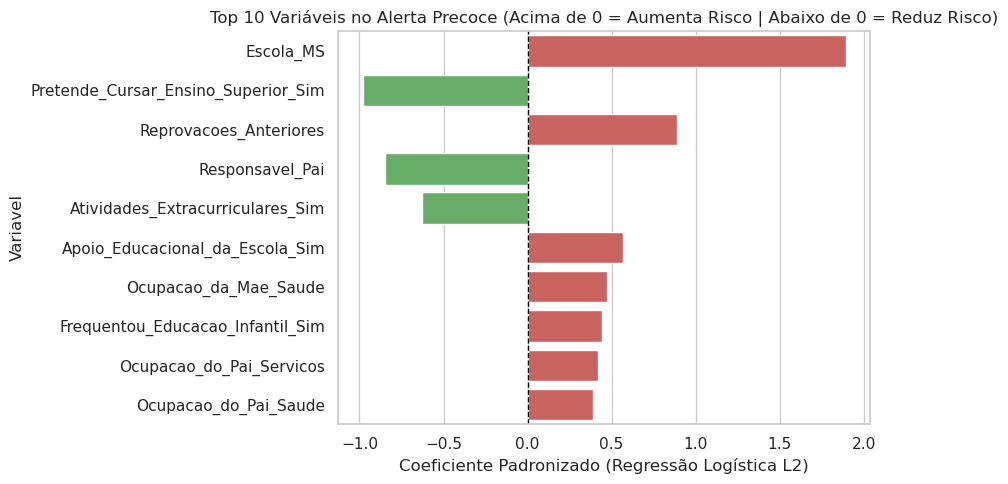

In [200]:
pipe_log_a = pipes_a["Reg. Logística (Balanced + L2 C=0.5)"]
nomes_vars = [n.replace("num__", "").replace("cat__", "") for n in pipe_log_a.named_steps["prep"].get_feature_names_out()]
coefs = pipe_log_a.named_steps["modelo"].coef_[0]

df_coefs = pd.DataFrame({
    "Variavel": nomes_vars,
    "Coeficiente": coefs,
    "Abs": np.abs(coefs)
}).sort_values("Abs", ascending=False).head(10)

plt.figure(figsize=(9, 5))
cores = ["#d9534f" if c > 0 else "#5cb85c" for c in df_coefs["Coeficiente"]]
sns.barplot(data=df_coefs, x="Coeficiente", y="Variavel", palette=cores)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Top 10 Variáveis no Alerta Precoce (Acima de 0 = Aumenta Risco | Abaixo de 0 = Reduz Risco)")
plt.xlabel("Coeficiente Padronizado (Regressão Logística L2)")
plt.tight_layout()
plt.show()

**Conclusão do gráfico de importância das variáveis (6.1):** As variáveis que mais aumentam o risco de reprovação logo no início do ano são o histórico de `Reprovacoes_Anteriores` e pertencer à escola `MS`, enquanto `Pretende_Cursar_Ensino_Superior_Sim`, maior `Tempo_de_Estudo_Semanal` e maior `Escolaridade_da_Mae` atuam como os principais fatores de proteção.

### 6.2 Boas Práticas Aplicadas
* **Prevenção de Vazamento de Dados (*Data Leakage*):** A separação entre treino (80%) e teste (20%) foi feita antes de qualquer padronização ou codificação, usando `Pipeline` e `ColumnTransformer` ajustados somente no treino.
* **Disponibilidade Temporal das Features:** Avaliamos separadamente o Cenário A (início do ano, sem notas do 1º e 2º períodos) e o Cenário B (após o 2º período), garantindo que cada feature estaria disponível no momento real da previsão.
* **Controle de *Overfitting* e Regularização:** Comparamos o desempenho entre treino e teste e aplicamos regularização L2 (Ridge e Logística com `C=0.5`), regularização L1 (Lasso) e limite de profundidade (`max_depth=5`) no Random Forest.
* **Tratamento de Classes Desbalanceadas:** Utilizamos `class_weight="balanced"` para lidar com a proporção de 15,41% de reprovados, elevando o Recall no teste de 10% para 65% no Cenário A (e 90% no Cenário B).

### 6.3 Limitações do Modelo e dos Dados e Conclusão Final
* **Contexto e Generalização:** Os dados referem-se a 649 alunos de duas escolas portuguesas na disciplina de Língua Portuguesa. O uso em escolas brasileiras ou em outras disciplinas requer novo treinamento com dados locais.
* **Respostas Autorrelatadas e Notas Zero:** Variáveis comportamentais (como consumo de álcool e tempo de estudo) dependem de questionário, podendo conter viés. Além disso, os 15 casos de nota final zero com zero faltas podem refletir transferência ou abandono não detalhado na base.
* **Custo de Falsos Positivos no Alerta Precoce:** No Cenário A, para encontrar 65% dos alunos que reprovariam, a precisão é de 38,2%. Por isso, a decisão apoiada pelo modelo deve ser sempre **oferecer suporte pedagógico e acolhimento**, sem jamais estigmatizar o estudante.